# DATA3001 Proposal: Data, Method and Initial Analysis

This notebook is a self-contained explanation of the Region A forecasting project. It documents **what data are currently available**, **where they came from**, **how they are checked and transformed**, and **how they can support the proposed 24-hour-to-72-hour trajectory forecasting analysis**.

The notebook separates completed preliminary analysis from future modelling work. Numerical results are calculated directly from `RegionA.csv` rather than typed manually.

## 1. Research objective and study design

The project studies whether the next 72 hourly positions of a surface drifter in Region A can be predicted from its preceding 24 hourly observations. The main forecasting variables are latitude, longitude, eastward velocity (`ve`) and northward velocity (`vn`). Quality-control and explanatory variables include position and velocity errors, positioning system, drogue-loss date, drogue type and drogue centre depth.

Region A covers **125–135°E and 25–35°N**, including the East China Sea and the upstream Kuroshio region. This area is scientifically useful because it contains spatially heterogeneous circulation rather than one uniform flow regime.

In [1]:
import os
from pathlib import Path

# Use writable cache folders so the notebook also runs cleanly in restricted environments.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/data3001-matplotlib")
os.environ.setdefault("XDG_CACHE_HOME", "/tmp/data3001-cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
Path(os.environ["XDG_CACHE_HOME"]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

LON_MIN, LON_MAX = 125.0, 135.0
LAT_MIN, LAT_MAX = 25.0, 35.0
INPUT_STEPS = 24
TARGET_STEPS = 72
WINDOW_STEPS = INPUT_STEPS + TARGET_STEPS
RANDOM_SEED = 3001

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "RegionA.csv").exists():
            return candidate
    raise FileNotFoundError(
        "RegionA.csv was not found. Start JupyterLab from the data3001-project folder."
    )

PROJECT_DIR = find_project_root()
DATA_PATH = PROJECT_DIR / "RegionA.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "proposal_notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data file:", DATA_PATH)

Project directory: /Users/roger/Documents/data3001-project
Data file: /Users/roger/Documents/data3001-project/RegionA.csv


## 2. Data source and provenance

The observations come from the **NOAA Global Drifter Program (GDP) one-hour interpolated quality-controlled dataset**. Surface drifters are satellite tracked and provide hourly position and current-velocity estimates. The project CSV was obtained from this dataset and spatially restricted to Region A.

Relevant source documentation:

- NOAA hourly drifter data: https://www.aoml.noaa.gov/phod/gdp/hourly_data.php
- NOAA NCEI record: https://www.ncei.noaa.gov/access/metadata/landing-page/bin/iso?id=gov.noaa.nodc%3AAOML-GDP-1hr
- Dataset DOI: https://doi.org/10.25921/x46c-3620

The code below detects and skips the optional units row that appears in an ERDDAP CSV export.

In [2]:
def read_erddap_csv(path):
    preview = pd.read_csv(path, nrows=1, low_memory=False)
    has_units_row = (
        "latitude" in preview.columns
        and not preview.empty
        and pd.isna(pd.to_numeric(preview.loc[0, "latitude"], errors="coerce"))
    )
    return pd.read_csv(
        path,
        skiprows=[1] if has_units_row else None,
        low_memory=False,
    )

raw = read_erddap_csv(DATA_PATH)
print(f"Raw data shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head(3))

Raw data shape: 562,944 rows × 20 columns


,ID,time,latitude,longitude,sst,flg_sst,ve,vn,err_lat,err_lon,err_ve,err_vn,gap,deploy_lat,deploy_lon,drogue_lost_date,location_type,DeployingShip,DrogueType,DrogueCenterDepth
0,116418,2015-08-23T21:00:00Z,25.252,134.600,NaN,0.000,0.328,0.337,0.000,0.000,0.049,0.063,"1,681.208",6.160,-153.650,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m
1,116418,2015-08-23T22:00:00Z,25.262,134.612,NaN,0.000,0.328,0.337,0.000,0.000,0.048,0.063,"1,681.208",6.160,-153.650,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m
2,116418,2015-08-23T23:00:00Z,25.273,134.624,NaN,0.000,0.328,0.337,0.000,0.000,0.083,0.063,"1,681.208",6.160,-153.650,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m


## 3. What variables are available?

| Variable | Role in the project |
|---|---|
| `ID`, `time` | Identify each drifter and order its observations |
| `latitude`, `longitude` | Forecast targets and trajectory positions |
| `ve`, `vn` | Eastward and northward velocity; predictors and physical baselines |
| `err_lat`, `err_lon` | Position-uncertainty information |
| `err_ve`, `err_vn` | Velocity-uncertainty information |
| `location_type` | Indicates GPS or Argos positioning |
| `drogue_lost_date` | Identifies whether the underwater drogue was still attached |
| `DrogueType`, `DrogueCenterDepth` | Additional drifter configuration information |
| `sst`, `flg_sst` | Sea-surface temperature and its quality flag; possible future predictors |

The **drogue** is an underwater sea anchor. After it is lost, a drifter is more strongly influenced by wind and waves, so drogue status may define an important forecasting regime. GPS and Argos are different satellite-positioning systems and may have different uncertainty characteristics.

In [3]:
column_inventory = pd.DataFrame({
    "column": raw.columns,
    "dtype_before_cleaning": raw.dtypes.astype(str).values,
    "missing_n": raw.isna().sum().values,
    "missing_pct": (100 * raw.isna().mean()).values,
})
display(column_inventory)

,column,dtype_before_cleaning,missing_n,missing_pct
0,ID,int64,0,0.000
1,time,str,0,0.000
2,latitude,float64,0,0.000
3,longitude,float64,0,0.000
4,sst,float64,28134,4.998
5,flg_sst,float64,2331,0.414
6,ve,float64,0,0.000
7,vn,float64,0,0.000
8,err_lat,float64,1049,0.186
9,err_lon,float64,1052,0.187


## 4. Cleaning and quality-control strategy

The data are ordered by drifter ID and time. The checks below identify duplicated ID–time observations, missing core variables, positions outside Region A, implausible velocities, positioning-system differences and missing quality-control fields. Flagged observations are **not automatically deleted** when a physical or near-coastal explanation is possible. In particular, apparent land observations require coastline-resolution and stranding checks before removal.

In [4]:
df = raw.copy()
df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
numeric_columns = [
    "latitude", "longitude", "sst", "ve", "vn",
    "err_lat", "err_lon", "err_ve", "err_vn",
    "gap", "deploy_lat", "deploy_lon",
]
for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

duplicate_rows = int(df.duplicated().sum())
duplicate_id_time = int(df.duplicated(["ID", "time"]).sum())

# Keep one record per ID-time pair after reporting duplicates.
df = df.drop_duplicates(["ID", "time"], keep="first")
df = df.sort_values(["ID", "time"]).reset_index(drop=True)
df["speed"] = np.hypot(df["ve"], df["vn"])
df["inside_region"] = (
    df["longitude"].between(LON_MIN, LON_MAX)
    & df["latitude"].between(LAT_MIN, LAT_MAX)
)

core = ["ID", "time", "latitude", "longitude", "ve", "vn"]
core_complete = df[core].notna().all(axis=1)
analysis_df = df.loc[core_complete & df["inside_region"]].copy()

quality_summary = pd.Series({
    "raw_rows": len(raw),
    "exact_duplicate_rows": duplicate_rows,
    "duplicate_ID_time_rows": duplicate_id_time,
    "rows_missing_a_core_variable": int((~core_complete).sum()),
    "rows_outside_Region_A": int((~df["inside_region"]).sum()),
    "analysis_rows_after_core_checks": len(analysis_df),
    "speed_above_2_m_per_s": int((analysis_df["speed"] > 2).sum()),
    "speed_above_3_m_per_s": int((analysis_df["speed"] > 3).sum()),
})
display(quality_summary.to_frame("value"))

,value
raw_rows,562944
exact_duplicate_rows,0
duplicate_ID_time_rows,0
rows_missing_a_core_variable,0
rows_outside_Region_A,0
analysis_rows_after_core_checks,562944
speed_above_2_m_per_s,245
speed_above_3_m_per_s,0


In [5]:
qc_columns = [
    "ID", "time", "latitude", "longitude", "ve", "vn",
    "err_lat", "err_lon", "err_ve", "err_vn",
    "location_type", "drogue_lost_date", "DrogueType",
    "DrogueCenterDepth",
]
qc_columns = [c for c in qc_columns if c in analysis_df.columns]
missing_table = pd.DataFrame({
    "missing_n": analysis_df[qc_columns].isna().sum(),
    "missing_pct": 100 * analysis_df[qc_columns].isna().mean(),
}).round(3)
display(missing_table)

if "location_type" in analysis_df.columns:
    location_table = analysis_df["location_type"].value_counts().to_frame("observations")
    location_table["percentage"] = 100 * location_table["observations"] / len(analysis_df)
    display(location_table.round(2))

,missing_n,missing_pct
ID,0,0.000
time,0,0.000
latitude,0,0.000
longitude,0,0.000
ve,0,0.000
vn,0,0.000
err_lat,1049,0.186
err_lon,1052,0.187
err_ve,24624,4.374
err_vn,24630,4.375


,observations,percentage
location_type,,
Argos,401989,71.410
GPS,160955,28.590


## 5. What data do we currently have?

This summary is generated from the cleaned analysis table. It provides the core evidence needed for the proposal's data-description and initial-analysis sections.

In [6]:
data_summary = pd.DataFrame({
    "Quantity": [
        "Study region",
        "Time coverage",
        "Hourly observations",
        "Unique drifters",
        "Core-variable missingness",
        "Positioning systems",
    ],
    "Result": [
        "125–135°E, 25–35°N",
        f"{analysis_df['time'].min().year}–{analysis_df['time'].max().year}",
        f"{len(analysis_df):,}",
        f"{analysis_df['ID'].nunique():,}",
        f"{100 * analysis_df[core].isna().to_numpy().mean():.3f}%",
        ", ".join(sorted(analysis_df['location_type'].dropna().astype(str).unique())),
    ],
})
display(data_summary)

,Quantity,Result
0,Study region,"125–135°E, 25–35°N"
1,Time coverage,1994–2022
2,Hourly observations,"562,944"
3,Unique drifters,521
4,Core-variable missingness,0.000%
5,Positioning systems,"Argos, GPS"


## 6. Initial spatial and temporal visualisation

The first panel measures how densely different parts of Region A were sampled. A blank cell means no observation was recorded there; without a coastline mask it should not automatically be interpreted as land. The second panel shows annual observation and drifter availability, which reveals that temporal coverage is uneven even though the full date range is 1994–2022.

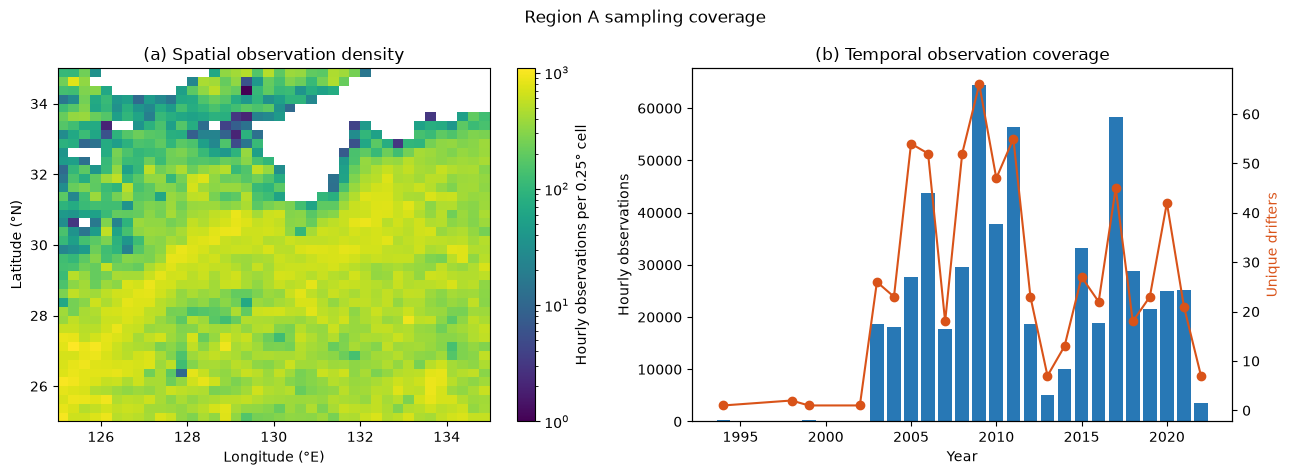

Saved: /Users/roger/Documents/data3001-project/outputs/proposal_notebook/region_A_spatial_temporal_coverage.png


In [7]:
grid_size = 0.25
lon_edges = np.arange(LON_MIN, LON_MAX + grid_size, grid_size)
lat_edges = np.arange(LAT_MIN, LAT_MAX + grid_size, grid_size)
density, _, _ = np.histogram2d(
    analysis_df["longitude"], analysis_df["latitude"],
    bins=[lon_edges, lat_edges],
)
masked_density = np.ma.masked_where(density.T == 0, density.T)

annual = (
    analysis_df.assign(year=analysis_df["time"].dt.year)
    .groupby("year")
    .agg(observations=("ID", "size"), drifters=("ID", "nunique"))
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
mesh = axes[0].pcolormesh(
    lon_edges, lat_edges, masked_density, shading="auto",
    cmap="viridis", norm=LogNorm(vmin=1, vmax=float(density.max())),
)
fig.colorbar(mesh, ax=axes[0], label="Hourly observations per 0.25° cell")
axes[0].set(
    xlabel="Longitude (°E)", ylabel="Latitude (°N)",
    title="(a) Spatial observation density",
    xlim=(LON_MIN, LON_MAX), ylim=(LAT_MIN, LAT_MAX),
)

axes[1].bar(annual.index, annual["observations"], color="#2878B5")
axes[1].set(
    xlabel="Year", ylabel="Hourly observations",
    title="(b) Temporal observation coverage",
)
ax2 = axes[1].twinx()
ax2.plot(annual.index, annual["drifters"], color="#D95319", marker="o", label="Drifters")
ax2.set_ylabel("Unique drifters", color="#D95319")

fig.suptitle("Region A sampling coverage")
fig.tight_layout()
coverage_path = OUTPUT_DIR / "region_A_spatial_temporal_coverage.png"
fig.savefig(coverage_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", coverage_path)

## 7. From many years of data to 24-hour and 72-hour samples

The multi-year archive is not treated as one trajectory. Observations are first grouped by drifter and ordered by time. Whenever the interval between adjacent records is outside 0.5–1.5 hours, a new continuous segment begins. A segment needs at least **96 consecutive hourly observations** to supply 24 input observations and 72 future target observations.

Notice that 96 hourly observations span 95 elapsed hours. Therefore the criterion is written as **96 observations**, not “96 hours”.

In [8]:
trajectory = analysis_df.sort_values(["ID", "time"]).copy()
trajectory["dt_hours"] = (
    trajectory.groupby("ID")["time"].diff().dt.total_seconds().div(3600)
)
trajectory["new_segment"] = (
    trajectory["dt_hours"].isna()
    | ~trajectory["dt_hours"].between(0.5, 1.5)
)
trajectory["segment_id"] = trajectory.groupby("ID")["new_segment"].cumsum()

segments = (
    trajectory.groupby(["ID", "segment_id"])
    .agg(
        start_time=("time", "min"),
        end_time=("time", "max"),
        n_observations=("time", "size"),
    )
    .reset_index()
)
segments["elapsed_hours"] = (
    segments["end_time"] - segments["start_time"]
).dt.total_seconds().div(3600)
segments["eligible_24_to_72"] = segments["n_observations"] >= WINDOW_STEPS
segments["overlapping_windows"] = (
    segments["n_observations"] - WINDOW_STEPS + 1
).clip(lower=0)

segment_summary = pd.Series({
    "continuous_segments": len(segments),
    "segments_with_at_least_96_observations": int(segments["eligible_24_to_72"].sum()),
    "eligible_percentage": 100 * segments["eligible_24_to_72"].mean(),
    "potential_overlapping_96_observation_windows": int(segments["overlapping_windows"].sum()),
})
display(segment_summary.to_frame("value"))
display(segments["n_observations"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

,value
continuous_segments,"2,058.000"
segments_with_at_least_96_observations,939.000
eligible_percentage,45.627
potential_overlapping_96_observation_windows,"443,295.000"


count   2,058.000
mean      273.539
std       455.874
min         1.000
50%        74.000
75%       340.250
90%       810.700
95%     1,141.300
99%     2,283.590
max     3,570.000
Name: n_observations, dtype: float64

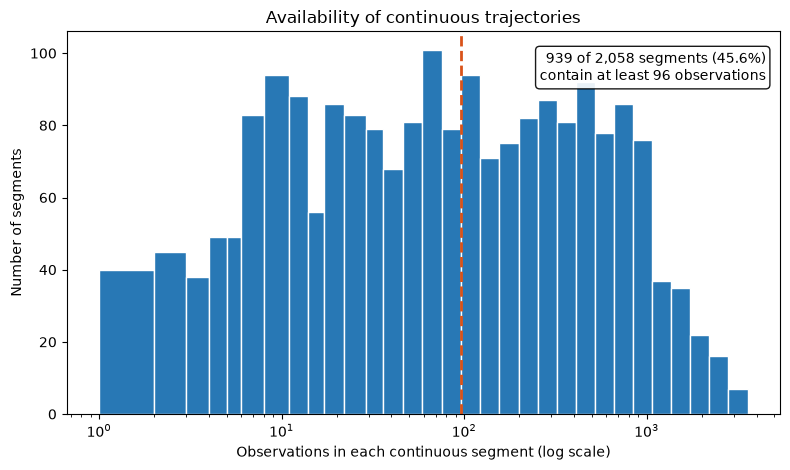

Saved: /Users/roger/Documents/data3001-project/outputs/proposal_notebook/region_A_segment_availability.png


In [9]:
segment_lengths = segments["n_observations"].clip(lower=1)
bins = np.unique(np.logspace(0, np.log10(segment_lengths.max() + 1), 35).astype(int))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(segment_lengths, bins=bins, color="#2878B5", edgecolor="white")
ax.axvline(WINDOW_STEPS, color="#D95319", linestyle="--", linewidth=2)
ax.set_xscale("log")
ax.set(
    xlabel="Observations in each continuous segment (log scale)",
    ylabel="Number of segments",
    title="Availability of continuous trajectories",
)
eligible_n = int(segments["eligible_24_to_72"].sum())
ax.text(
    0.98, 0.95,
    f"{eligible_n:,} of {len(segments):,} segments ({100*eligible_n/len(segments):.1f}%)\n"
    "contain at least 96 observations",
    transform=ax.transAxes, ha="right", va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9},
)
fig.tight_layout()
segment_path = OUTPUT_DIR / "region_A_segment_availability.png"
fig.savefig(segment_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", segment_path)

## 8. Example of one 24-step input and 72-step target

The plot below turns the sample-construction rule into a concrete example. Blue points are the 24 positions supplied to a forecasting method. Orange points are the following 72 observed positions that the method must predict. Sliding this window can create many cases from a long segment, but adjacent windows are strongly dependent and must not be described as independent samples.

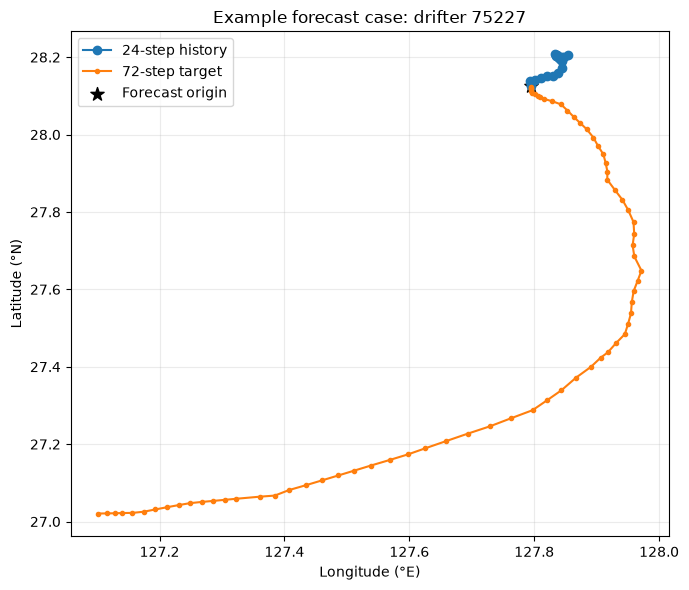

Input time range : 2008-09-03 18:00:00+00:00 to 2008-09-04 17:00:00+00:00
Target time range: 2008-09-04 18:00:00+00:00 to 2008-09-07 17:00:00+00:00
Saved: /Users/roger/Documents/data3001-project/outputs/proposal_notebook/example_24_to_72_forecast_case.png


In [10]:
eligible_segments = segments.loc[segments["eligible_24_to_72"]].copy()
example_meta = eligible_segments.iloc[(eligible_segments["n_observations"] - 120).abs().argmin()]
example = trajectory.loc[
    (trajectory["ID"] == example_meta["ID"])
    & (trajectory["segment_id"] == example_meta["segment_id"])
].sort_values("time").iloc[:WINDOW_STEPS].copy()

history = example.iloc[:INPUT_STEPS]
future = example.iloc[INPUT_STEPS:]

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(history["longitude"], history["latitude"], "o-", label="24-step history")
ax.plot(future["longitude"], future["latitude"], "o-", markersize=3, label="72-step target")
ax.scatter(history.iloc[-1]["longitude"], history.iloc[-1]["latitude"], s=100, marker="*", color="black", label="Forecast origin")
ax.set(
    xlabel="Longitude (°E)", ylabel="Latitude (°N)",
    title=f"Example forecast case: drifter {int(example_meta['ID'])}",
)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
example_path = OUTPUT_DIR / "example_24_to_72_forecast_case.png"
fig.savefig(example_path, dpi=200, bbox_inches="tight")
plt.show()

print("Input time range :", history["time"].min(), "to", history["time"].max())
print("Target time range:", future["time"].min(), "to", future["time"].max())
print("Saved:", example_path)

## 9. Leakage-safe train, calibration and test split

All observations from the same physical drifter must remain in one partition. Splitting individual rows or overlapping windows would leak highly related trajectory information into different datasets. The proposed split assigns 70% of drifter IDs to training, 15% to calibration and the remaining 15% to testing.

- **Training:** fit baselines and learned model parameters.
- **Calibration:** tune models and calibrate conformal prediction regions.
- **Test:** perform the final comparison once, after all choices are fixed.

In [11]:
rng = np.random.default_rng(RANDOM_SEED)
drifter_ids = analysis_df["ID"].drop_duplicates().to_numpy().copy()
rng.shuffle(drifter_ids)

n_train = int(0.70 * len(drifter_ids))
n_calibration = int(0.15 * len(drifter_ids))
train_ids = set(drifter_ids[:n_train])
calibration_ids = set(drifter_ids[n_train:n_train + n_calibration])
test_ids = set(drifter_ids[n_train + n_calibration:])

split_table = pd.DataFrame({
    "partition": ["Training", "Calibration", "Test"],
    "drifters": [len(train_ids), len(calibration_ids), len(test_ids)],
})
split_table["percentage"] = 100 * split_table["drifters"] / len(drifter_ids)
display(split_table.round(2))

assert train_ids.isdisjoint(calibration_ids)
assert train_ids.isdisjoint(test_ids)
assert calibration_ids.isdisjoint(test_ids)
print("No drifter IDs overlap between partitions.")

,partition,drifters,percentage
0,Training,364,69.870
1,Calibration,78,14.970
2,Test,79,15.160


No drifter IDs overlap between partitions.


## 10. Proposed forecasting methods

Two transparent baselines establish whether a learned method adds useful predictive information:

1. **Velocity-persistence baseline:** retain the latest observed eastward and northward velocities and integrate them forward over the 72-hour horizon. This is not the same as keeping the drifter stationary.
2. **Spatial mean-flow baseline:** estimate the average velocity field from training drifters only, then advect each test drifter through the corresponding grid-cell flow.

These baselines can be compared with a statistical or machine-learning model such as ARIMA, a feed-forward neural network (FNN), or a spatiotemporal neural network (STN). Every method must use identical forecast origins, data partitions and evaluation cases. The proposal need not claim that all candidate models have already been fitted.

## 11. Evaluation plan

Prediction error is the geographic separation between the predicted and observed positions, measured in kilometres. Reporting only one overall RMSE would hide how error grows with forecast lead time. The planned evaluation therefore includes:

- geographic separation error for lead times 1–72 hours;
- errors at 24, 48 and 72 hours;
- average or integrated error across the complete 72-hour trajectory;
- final displacement error and forecast skill relative to each baseline;
- optional along-track and cross-track error to distinguish timing error from directional error.

Model selection and tuning use only training/calibration data. The test drifters remain untouched until the final evaluation.

## 12. Regime comparison and uncertainty

The spatial speed structure suggests that Region A contains different dynamical environments. Later analysis can combine bathymetry and flow structure to define regimes, then compare forecast errors between fast-current, weak-current, near-coastal and drogue-status groups. Regime definitions must be constructed without using test outcomes.

Conformal prediction can convert point forecasts into lead-time-specific prediction regions. Calibration-drifter residuals determine the region size, while the independent test set is used to report empirical coverage and prediction-region area. A useful method should achieve the intended coverage without producing unnecessarily large regions.

## 13. Proposal-ready interpretation

The preliminary analysis confirms that the project is feasible: the core forecasting variables are complete, both GPS and Argos observations are represented, and a substantial number of continuous trajectories can support the proposed sample design. Spatial and temporal sampling are uneven, so forecast performance should be examined across locations, years and dynamical regimes rather than reported as a single pooled number.

The 443,295 possible overlapping windows are **not** 443,295 independent samples. Final forecast origins should be temporally spaced using velocity autocorrelation and a Lagrangian integral-timescale analysis. Drifter-level partitioning remains necessary even after temporal spacing.

In [12]:
proposal_summary = pd.DataFrame({
    "Quantity": [
        "Study region", "Time coverage", "Hourly observations",
        "Unique drifters", "Continuous segments",
        "Eligible segments (≥96 observations)",
    ],
    "Preliminary result": [
        "125–135°E, 25–35°N",
        f"{analysis_df['time'].min().year}–{analysis_df['time'].max().year}",
        f"{len(analysis_df):,}",
        f"{analysis_df['ID'].nunique():,}",
        f"{len(segments):,}",
        f"{eligible_n:,} ({100 * eligible_n / len(segments):.1f}%)",
    ],
})
display(proposal_summary)

summary_path = OUTPUT_DIR / "proposal_data_summary.csv"
proposal_summary.to_csv(summary_path, index=False)
print("Saved:", summary_path)

,Quantity,Preliminary result
0,Study region,"125–135°E, 25–35°N"
1,Time coverage,1994–2022
2,Hourly observations,"562,944"
3,Unique drifters,521
4,Continuous segments,"2,058"
5,Eligible segments (≥96 observations),939 (45.6%)


Saved: /Users/roger/Documents/data3001-project/outputs/proposal_notebook/proposal_data_summary.csv


## 14. Completed work versus next steps

### Completed in this notebook

- documented the NOAA GDP source and available variables;
- checked duplicates, missing core values, regional boundaries and extreme speeds;
- summarised GPS/Argos and quality-control variables;
- visualised spatial and temporal sampling;
- constructed continuous hourly trajectory segments;
- demonstrated the 24-input/72-target sample design;
- verified the feasibility of a drifter-level train/calibration/test split.

### Remaining project work

- review near-shore/land-mask flags rather than deleting them automatically;
- estimate velocity autocorrelation and choose forecast-origin spacing;
- implement velocity-persistence and training-only spatial mean-flow baselines;
- fit and tune the selected learned model;
- compare lead-time-specific geographic errors on held-out drifters;
- define dynamical regimes and compare performance;
- calibrate and evaluate conformal prediction regions.